# Uber Fare Price Prediction

**Practical:** Predict Uber ride fare using Linear Regression and Random Forest Regression.

**Dataset required:** `uber.csv` (Kaggle Uber Fares Dataset)

Keep `uber.csv` in the **same folder** as this notebook, then choose **Run → Run All Cells**.

This notebook performs:
1. Data preprocessing
2. Outlier identification and removal
3. Correlation analysis
4. Linear Regression and Random Forest Regression
5. Model evaluation and comparison using R², RMSE and MAE


In [1]:
# Install any missing libraries automatically
import importlib.util
import subprocess
import sys

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn"
}

missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

print("All required libraries are ready.")

All required libraries are ready.


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# 1. Load the dataset
df = pd.read_csv("uber.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5



Missing values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [6]:
# 2. Data preprocessing
# Remove unnecessary columns if they exist
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

# Remove rows with missing values
df = df.dropna().copy()

# Convert pickup date and time
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df = df.dropna(subset=["pickup_datetime"]).copy()

# Extract useful date and time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

# Remove original datetime column
df = df.drop(columns=["pickup_datetime"])

# Remove invalid fare, passenger and coordinate values
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90))
].copy()

# Calculate geographical distance using Haversine formula
def calculate_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (np.sin(dlat / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance"] = calculate_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Remove zero and unusually long trips
df = df[(df["distance"] > 0) & (df["distance"] < 100)].copy()

print("Shape after preprocessing:", df.shape)
display(df.head())

Shape after preprocessing: (193191, 10)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,4.475450


Number of outliers: 16540
Lower limit: -3.75
Upper limit: 22.25


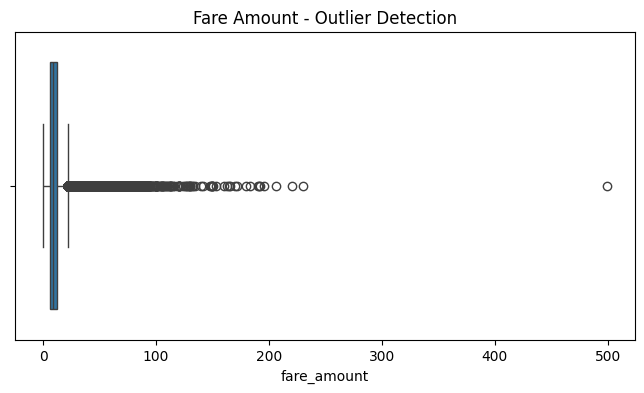

Shape after removing outliers: (176651, 10)


In [7]:
# 3. Identify outliers using IQR method
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower_limit) |
    (df["fare_amount"] > upper_limit)
]

print("Number of outliers:", len(outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

# Visualize outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount - Outlier Detection")
plt.show()

# Remove fare outliers
df = df[
    df["fare_amount"].between(lower_limit, upper_limit)
].copy()

print("Shape after removing outliers:", df.shape)

Correlation Matrix:


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,distance
fare_amount,1.000000,0.001204,-0.002014,0.002047,-0.002214,0.013017,-0.013121,0.006575,0.026705,0.723498
pickup_longitude,0.001204,1.000000,-0.993709,0.999963,-0.993716,0.009836,0.002746,0.018511,-0.007082,-0.008440
pickup_latitude,-0.002014,-0.993709,1.000000,-0.993727,0.999953,-0.010161,-0.002101,-0.019015,0.007518,0.008686
dropoff_longitude,0.002047,0.999963,-0.993727,1.000000,-0.993691,0.009861,0.002455,0.018477,-0.007092,-0.007633
dropoff_latitude,-0.002214,-0.993716,0.999953,-0.993691,1.000000,-0.010129,-0.002171,-0.019038,0.007504,0.008949
passenger_count,0.013017,0.009836,-0.010161,0.009861,-0.010129,1.000000,0.015268,0.002853,0.008511,0.000195
hour,-0.013121,0.002746,-0.002101,0.002455,-0.002171,0.015268,1.000000,0.005660,-0.003065,-0.032688
day,0.006575,0.018511,-0.019015,0.018477,-0.019038,0.002853,0.005660,1.000000,-0.016307,0.006123
month,0.026705,-0.007082,0.007518,-0.007092,0.007504,0.008511,-0.003065,-0.016307,1.000000,0.005301
distance,0.723498,-0.008440,0.008686,-0.007633,0.008949,0.000195,-0.032688,0.006123,0.005301,1.000000


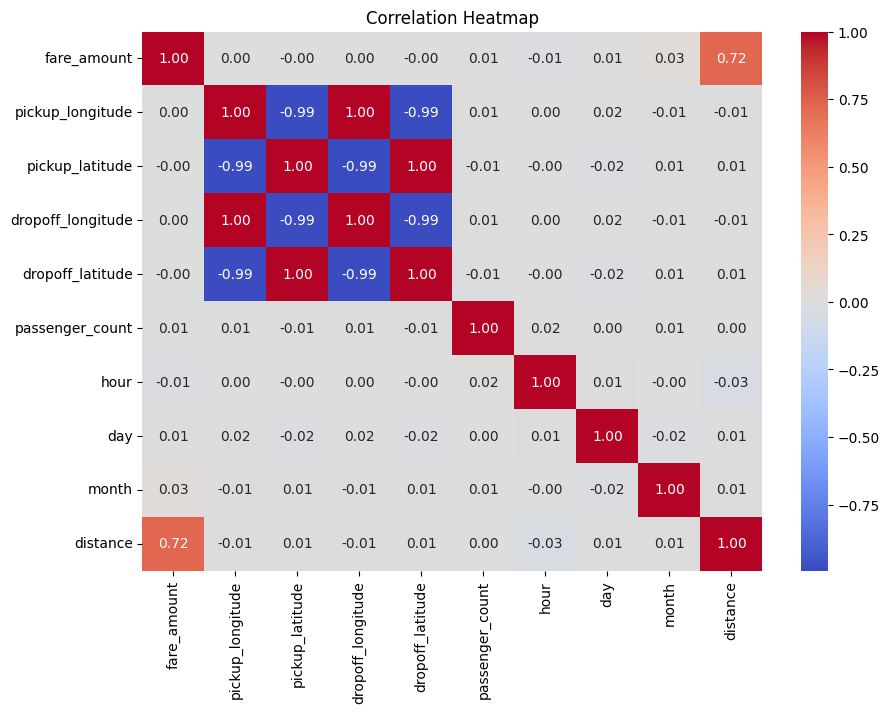

In [8]:
# 4. Correlation analysis
correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
display(correlation)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [9]:
# 5. Split data into input features and target
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Use a manageable training sample for faster Random Forest execution
if len(X_train) > 20000:
    X_train = X_train.sample(n=20000, random_state=42)
    y_train = y_train.loc[X_train.index]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 20000
Testing records: 35331


In [10]:
# 6. Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
# 7. Random Forest Regression model
random_model = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)
random_model.fit(X_train, y_train)

random_predictions = random_model.predict(X_test)

print("Random Forest model trained successfully.")

In [ ]:
# 8. Evaluate and compare both models
def evaluate_model(actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    return r2, rmse, mae

lr_scores = evaluate_model(y_test, linear_predictions)
rf_scores = evaluate_model(y_test, random_predictions)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "R2 Score": [lr_scores[0], rf_scores[0]],
    "RMSE": [lr_scores[1], rf_scores[1]],
    "MAE": [lr_scores[2], rf_scores[2]]
})

print("Model Performance Comparison:")
display(results)

# Compare models
if rf_scores[0] > lr_scores[0]:
    print("Random Forest Regression performs better based on R2 score.")
else:
    print("Linear Regression performs better based on R2 score.")

In [ ]:
# 9. Plot model comparison
results.set_index("Model")[["R2 Score", "RMSE", "MAE"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Conclusion

The Uber fare prediction task was completed using Linear Regression and Random Forest Regression.

- The dataset was cleaned and preprocessed.
- Outliers were identified using the IQR method.
- Correlation was examined using a heatmap.
- Both regression models were trained and evaluated.
- R², RMSE and MAE were used to compare model performance.

The model with the higher R² and lower RMSE/MAE provides better performance on this test set.